In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from pathlib import Path
import os

PROJECT_DIR = Path(os.environ.get("RETAIL_PROJECT_DIR", Path.cwd())).resolve()
if not (PROJECT_DIR / "data").is_dir():
    PROJECT_DIR = next(
        (parent for parent in PROJECT_DIR.parents if (parent / "data").is_dir()),
        Path("/content/drive/MyDrive/Colab Notebooks/Retail Sales Prediction")
    )
DATA_DIR = PROJECT_DIR / "data"

project_dir = str(PROJECT_DIR)

print("Project folder exists:", os.path.exists(project_dir))

Project folder exists: True


In [4]:
# Load the cleaned transaction dataset

file_path = DATA_DIR / "retail_cleaned.csv"

retail = pd.read_csv(file_path)

retail["InvoiceDate"] = pd.to_datetime(
    retail["InvoiceDate"], errors="coerce"
)

print("Dataset shape:", retail.shape)
print("Date range:", retail["InvoiceDate"].min(),
      "to", retail["InvoiceDate"].max())

display(retail.head())

Dataset shape: (410763, 10)
Date range: 2009-12-01 07:45:00 to 2010-12-09 20:01:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,30.0


In [5]:
# Prepare product-level demand data

# Keep valid sales transactions
sales = retail.dropna(
    subset=["InvoiceDate", "StockCode", "Quantity"]
).copy()

sales["Invoice"] = sales["Invoice"].astype(str)

if "IsCancelled" in sales.columns:
    sales = sales[~sales["IsCancelled"]].copy()
else:
    sales = sales[~sales["Invoice"].str.startswith("C")].copy()

sales = sales[sales["Quantity"] > 0].copy()

print("Valid sales rows:", len(sales))
print("Unique products:", sales["StockCode"].nunique())

Valid sales rows: 400947
Unique products: 4017


In [6]:
# Aggregate daily demand by product

daily_demand = (
    sales.groupby([
        "StockCode",
        pd.Grouper(key="InvoiceDate", freq="D")
    ])["Quantity"]
    .sum()
    .reset_index()
)

daily_demand.rename(
    columns={"InvoiceDate": "Date", "Quantity": "DailyDemand"},
    inplace=True
)

print("Daily demand shape:", daily_demand.shape)
display(daily_demand.head())

Daily demand shape: (223833, 3)


,StockCode,Date,DailyDemand
0,10002,2009-12-01,12
1,10002,2009-12-03,6
2,10002,2009-12-04,73
3,10002,2009-12-06,49
4,10002,2009-12-07,2


In [7]:
# Select a product and forecast its demand

product_sales = (
    sales.groupby("StockCode")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

selected_product = product_sales.index[0]

print("Selected product:", selected_product)
print("Total quantity sold:", product_sales.iloc[0])

Selected product: 21212
Total quantity sold: 57505


In [8]:
product_daily = (
    daily_demand[daily_demand["StockCode"] == selected_product]
    .set_index("Date")["DailyDemand"]
    .sort_index()
)

product_daily = product_daily.asfreq("D", fill_value=0)

display(product_daily.head())

,DailyDemand
Date,
2009-12-01,294
2009-12-02,574
2009-12-03,182
2009-12-04,193
2009-12-05,48


In [9]:
# Forecast demand for the next 30 days

forecast_horizon = 30

# Use the most recent 28 days to estimate daily demand
recent_demand = product_daily.tail(28)

average_daily_demand = recent_demand.mean()

future_dates = pd.date_range(
    start=product_daily.index.max() + pd.Timedelta(days=1),
    periods=forecast_horizon,
    freq="D"
)

forecast_df = pd.DataFrame({
    "Date": future_dates,
    "ForecastDemand": average_daily_demand
})

print("Average daily demand:", round(average_daily_demand, 2))
print("Forecast demand for 30 days:",
      round(forecast_df["ForecastDemand"].sum(), 2))

display(forecast_df.head())

Average daily demand: 180.21
Forecast demand for 30 days: 5406.43


,Date,ForecastDemand
0,2010-12-10,180.214286
1,2010-12-11,180.214286
2,2010-12-12,180.214286
3,2010-12-13,180.214286
4,2010-12-14,180.214286


In [10]:
# Calculate safety stock and reorder point

# Example planning assumptions — replace with real supplier data
lead_time_days = 7
service_level_z = 1.645

average_daily_demand = product_daily.mean()
daily_demand_std = product_daily.std(ddof=1)

if pd.isna(daily_demand_std):
    daily_demand_std = 0

safety_stock = (
    service_level_z
    * daily_demand_std
    * np.sqrt(lead_time_days)
)

reorder_point = (
    average_daily_demand * lead_time_days
    + safety_stock
)

print("Average daily demand:", round(average_daily_demand, 2))
print("Daily demand standard deviation:", round(daily_demand_std, 2))
print("Lead time:", lead_time_days, "days")
print("Safety stock:", int(np.ceil(safety_stock)))
print("Reorder point:", int(np.ceil(reorder_point)))

Average daily demand: 153.76
Daily demand standard deviation: 184.35
Lead time: 7 days
Safety stock: 803
Reorder point: 1879


In [11]:
# Calculate a suggested replenishment quantity

# Example only: replace with actual inventory and on-order quantities
current_stock = 20
on_order_quantity = 0
backorders = 0

inventory_position = (
    current_stock + on_order_quantity - backorders
)

target_stock = (
    average_daily_demand * (lead_time_days + 30)
    + safety_stock
)

reorder_quantity = max(
    0,
    int(np.ceil(target_stock - inventory_position))
)

should_reorder = inventory_position <= reorder_point

print("Current stock:", current_stock)
print("Inventory position:", inventory_position)
print("Reorder point:", int(np.ceil(reorder_point)))
print("Should reorder:", should_reorder)
print("Suggested replenishment quantity:", reorder_quantity)

Current stock: 20
Inventory position: 20
Reorder point: 1879
Should reorder: True
Suggested replenishment quantity: 6472


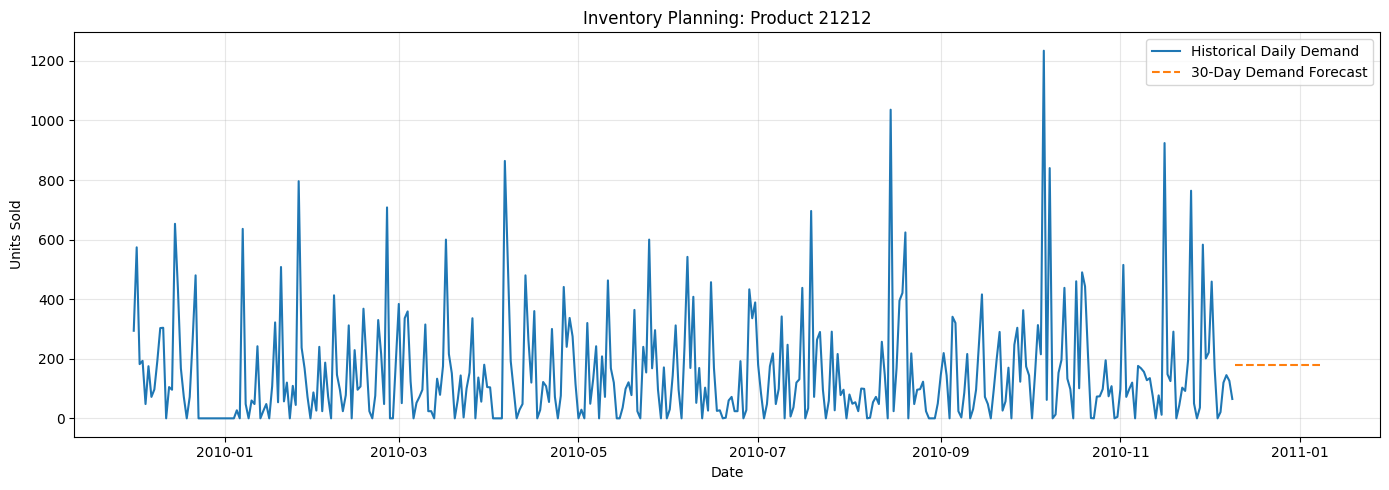

In [12]:
# Visualize historical and forecast demand

plt.figure(figsize=(14, 5))

plt.plot(
    product_daily.index,
    product_daily.values,
    label="Historical Daily Demand"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["ForecastDemand"],
    label="30-Day Demand Forecast",
    linestyle="--"
)

plt.title(f"Inventory Planning: Product {selected_product}")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
# Save the forecast and inventory recommendation

inventory_result = pd.DataFrame([{
    "StockCode": selected_product,
    "AverageDailyDemand": average_daily_demand,
    "LeadTimeDays": lead_time_days,
    "SafetyStock": int(np.ceil(safety_stock)),
    "ReorderPoint": int(np.ceil(reorder_point)),
    "CurrentStock_Assumed": current_stock,
    "InventoryPosition": inventory_position,
    "ShouldReorder": should_reorder,
    "SuggestedReorderQuantity": reorder_quantity
}])

inventory_result.to_csv(
    DATA_DIR / "inventory_recommendation.csv",
    index=False
)

forecast_df.to_csv(
    DATA_DIR / "product_demand_forecast.csv",
    index=False
)

print("Inventory recommendation and demand forecast saved.")
display(inventory_result)

Inventory recommendation and demand forecast saved.


,StockCode,AverageDailyDemand,LeadTimeDays,SafetyStock,ReorderPoint,CurrentStock_Assumed,InventoryPosition,ShouldReorder,SuggestedReorderQuantity
0,21212,153.756684,7,803,1879,20,20,True,6472


In [14]:
# Split historical demand into training and testing periods

# Ensure the daily series is sorted
product_daily = product_daily.sort_index().asfreq("D", fill_value=0)

# Hold out the last 30 days
test_days = 30

if len(product_daily) <= test_days + 7:
    raise ValueError("Not enough daily history for this evaluation.")

train = product_daily.iloc[:-test_days]
test = product_daily.iloc[-test_days:]

print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())
print("Training days:", len(train))
print("Testing days:", len(test))

Training period: 2009-12-01 00:00:00 to 2010-11-09 00:00:00
Testing period: 2010-11-10 00:00:00 to 2010-12-09 00:00:00
Training days: 344
Testing days: 30


In [15]:
# Generate forecasts

# Baseline 1: Mean daily demand in training data
mean_forecast = np.full(len(test), train.mean())

# Baseline 2: Average demand over the last 7 training days
moving_avg_forecast = np.full(
    len(test),
    train.tail(7).mean()
)

forecast_comparison = pd.DataFrame({
    "Date": test.index,
    "ActualDemand": test.values,
    "MeanForecast": mean_forecast,
    "MovingAverageForecast": moving_avg_forecast
})

display(forecast_comparison.head())

,Date,ActualDemand,MeanForecast,MovingAverageForecast
0,2010-11-10,128,151.732558,112.857143
1,2010-11-11,135,151.732558,112.857143
2,2010-11-12,74,151.732558,112.857143
3,2010-11-13,0,151.732558,112.857143
4,2010-11-14,77,151.732558,112.857143


In [16]:
# Calculate MAE and RMSE

from sklearn.metrics import mean_absolute_error, mean_squared_error

results = []

for model_name, predictions in [
    ("Historical Mean", mean_forecast),
    ("7-Day Moving Average", moving_avg_forecast)
]:
    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(test, predictions),
        "RMSE": np.sqrt(mean_squared_error(test, predictions))
    })

evaluation_df = pd.DataFrame(results).sort_values("MAE")

display(evaluation_df.round(2))

,Model,MAE,RMSE
1,7-Day Moving Average,131.18,229.29
0,Historical Mean,137.59,221.59


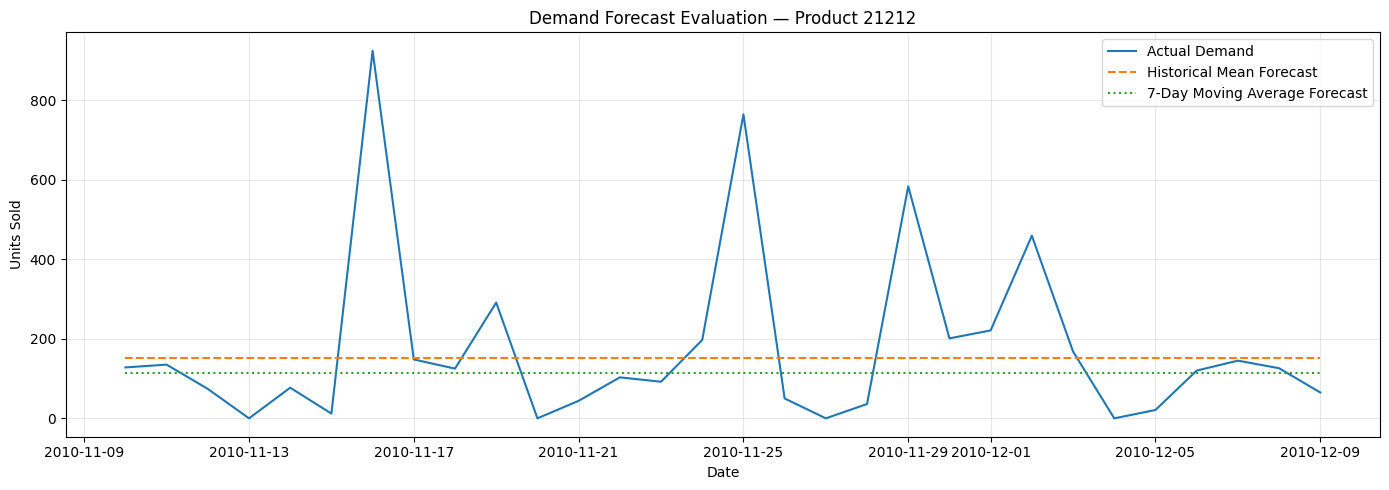

In [17]:
# Plot actual versus forecast demand

plt.figure(figsize=(14, 5))

plt.plot(
    test.index, test.values,
    label="Actual Demand"
)

plt.plot(
    test.index, mean_forecast,
    linestyle="--",
    label="Historical Mean Forecast"
)

plt.plot(
    test.index, moving_avg_forecast,
    linestyle=":",
    label="7-Day Moving Average Forecast"
)

plt.title(f"Demand Forecast Evaluation — Product {selected_product}")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# optimize inventory for multiple products

# Select top 20 products by total units sold
top_products = (
    sales.groupby("StockCode")["Quantity"]
    .sum()
    .nlargest(20)
    .index
)

# Planning assumptions — replace with real values when available
lead_time_days = 7
review_period_days = 7
service_level_z = 1.645  # Approx. 95% one-sided service level

recommendations = []

for product in top_products:
    # Build continuous daily demand history
    demand = (
        daily_demand.loc[
            daily_demand["StockCode"] == product
        ]
        .set_index("Date")["DailyDemand"]
        .sort_index()
        .asfreq("D", fill_value=0)
    )

    if len(demand) < 14:
        continue

    # Estimate demand from the most recent 7 days
    avg_daily_demand = demand.tail(7).mean()

    # Estimate variability from historical daily demand
    daily_std = demand.std(ddof=1)
    if pd.isna(daily_std):
        daily_std = 0

    # Safety stock and reorder point
    safety_stock = (
        service_level_z * daily_std * np.sqrt(lead_time_days)
    )

    reorder_point = (
        avg_daily_demand * lead_time_days + safety_stock
    )

    # Target stock for lead time + review period
    target_stock = (
        avg_daily_demand * (lead_time_days + review_period_days)
        + safety_stock
    )

    recommendations.append({
        "StockCode": product,
        "AvgDailyDemand": avg_daily_demand,
        "DailyDemandStd": daily_std,
        "LeadTimeDays": lead_time_days,
        "SafetyStock": int(np.ceil(safety_stock)),
        "ReorderPoint": int(np.ceil(reorder_point)),
        "TargetStock": int(np.ceil(target_stock))
    })

inventory_df = pd.DataFrame(recommendations)

display(inventory_df.round(2))

,StockCode,AvgDailyDemand,DailyDemandStd,LeadTimeDays,SafetyStock,ReorderPoint,TargetStock
0,21212,92.14,184.35,7,803,1448,2093
1,85123A,144.71,173.09,7,754,1767,2780
2,84077,68.57,400.04,7,1742,2222,2702
3,85099B,110.14,169.18,7,737,1508,2279
4,17003,134.14,739.52,7,3219,4158,5097
5,84879,105.86,229.21,7,998,1739,2480
6,84991,35.57,141.67,7,617,866,1115
7,21977,37.86,132.16,7,576,841,1106
8,22197,97.57,213.59,7,930,1613,2296
9,37410,6.86,1769.94,7,7704,7752,7800


In [19]:
# Save the recommendations

output_path = os.path.join(
    DATA_DIR,
    "top20_inventory_recommendations.csv"
)

inventory_df.to_csv(output_path, index=False)

print("Saved inventory recommendations to:")
print(output_path)

Saved inventory recommendations to:
/content/drive/MyDrive/Colab Notebooks/Retail Sales Prediction/top20_inventory_recommendations.csv


In [20]:
# Identify high-priority products

# Create inventory planning priority indicators
inventory_df["DemandVariability"] = (
    inventory_df["DailyDemandStd"] /
    inventory_df["AvgDailyDemand"].replace(0, np.nan)
)

# Rank products by estimated safety stock
inventory_df["SafetyStockRank"] = (
    inventory_df["SafetyStock"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

# Sort products by safety stock required
priority_df = inventory_df.sort_values(
    by="SafetyStock",
    ascending=False
).reset_index(drop=True)

display(priority_df.round(2))

,StockCode,AvgDailyDemand,DailyDemandStd,LeadTimeDays,SafetyStock,ReorderPoint,TargetStock,DemandVariability,SafetyStockRank
0,37410,6.86,1769.94,7,7704,7752,7800,258.12,1
1,17003,134.14,739.52,7,3219,4158,5097,5.51,2
2,21982,26.00,720.64,7,3137,3319,3501,27.72,3
3,21984,10.71,609.78,7,2654,2729,2804,56.91,4
4,21980,15.43,559.52,7,2436,2544,2652,36.27,5
5,84347,64.43,531.18,7,2312,2763,3214,8.24,6
6,84077,68.57,400.04,7,1742,2222,2702,5.83,7
7,84568,205.71,244.39,7,1064,2504,3944,1.19,8
8,84879,105.86,229.21,7,998,1739,2480,2.17,9
9,22197,97.57,213.59,7,930,1613,2296,2.19,10


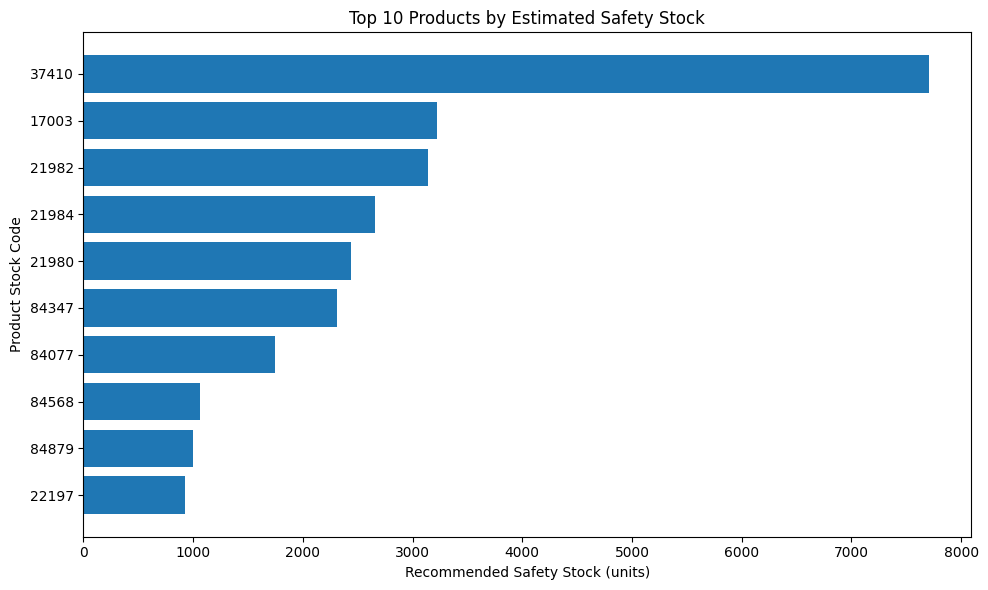

In [21]:
# Visualize the top 10 products by safety stock

top_10 = priority_df.head(10).sort_values("SafetyStock")

plt.figure(figsize=(10, 6))
plt.barh(
    top_10["StockCode"].astype(str),
    top_10["SafetyStock"]
)

plt.xlabel("Recommended Safety Stock (units)")
plt.ylabel("Product Stock Code")
plt.title("Top 10 Products by Estimated Safety Stock")
plt.tight_layout()
plt.show()

In [22]:
# Export the inventory recommendations

output_path = os.path.join(DATA_DIR, "inventory_optimization_recommendations.csv")

priority_df.to_csv(output_path, index=False)

print(f"Inventory recommendations saved to: {output_path}")

Inventory recommendations saved to: inventory_optimization_recommendations.csv


In [23]:
from google.colab import files

files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# LSTM demand forecasting model using PyTorch Lightning

In [25]:
!pip install -q lightning

In [26]:
import torch
import torch.nn as nn
import lightning.pytorch as pl

from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

pl.seed_everything(42, workers=True)

print("PyTorch version:", torch.__version__)
print("Lightning version:", pl.__version__)
print("GPU available:", torch.cuda.is_available())

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42


PyTorch version: 2.11.0+cpu
Lightning version: 2.6.6
GPU available: False


In [27]:
# Prepare daily demand data

# Prepare daily demand for the selected product
series = product_daily.copy()

series = series.sort_index().asfreq("D", fill_value=0)
series = series.astype("float32")

print("Selected product:", selected_product)
print("Number of daily observations:", len(series))
print("Date range:", series.index.min(), "to", series.index.max())

display(series.head())

Selected product: 21212
Number of daily observations: 374
Date range: 2009-12-01 00:00:00 to 2010-12-09 00:00:00


,DailyDemand
Date,
2009-12-01,294.0
2009-12-02,574.0
2009-12-03,182.0
2009-12-04,193.0
2009-12-05,48.0


In [28]:
# Scale the data and create sequences

lookback = 28
forecast_horizon = 7

if len(series) < lookback + forecast_horizon + 30:
    raise ValueError(
        "Not enough daily observations for this setup. "
        "Use a shorter lookback or forecast horizon."
    )

values = series.to_numpy().reshape(-1, 1)

# Chronological split: reserve the final 30 days for evaluation
split_idx = len(values) - 30

scaler = MinMaxScaler()
scaler.fit(values[:split_idx])

scaled_values = scaler.transform(values).astype(np.float32).flatten()

def create_sequences(data, lookback=28, horizon=7, end_idx=None):
    X, y = [], []

    if end_idx is None:
        end_idx = len(data)

    for i in range(lookback, end_idx - horizon + 1):
        X.append(data[i - lookback:i])
        y.append(data[i:i + horizon])

    return np.array(X), np.array(y)

# Training sequences end before the evaluation period
X_train, y_train = create_sequences(
    scaled_values,
    lookback=lookback,
    horizon=forecast_horizon,
    end_idx=split_idx
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (310, 28)
y_train shape: (310, 7)


In [29]:
# Create training and validation sets

validation_size = max(1, int(len(X_train) * 0.15))

X_fit = X_train[:-validation_size]
y_fit = y_train[:-validation_size]

X_val = X_train[-validation_size:]
y_val = y_train[-validation_size:]

train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_fit).unsqueeze(-1),
        torch.tensor(y_fit)
    ),
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_val).unsqueeze(-1),
        torch.tensor(y_val)
    ),
    batch_size=32,
    shuffle=False
)

print("Training samples:", len(X_fit))
print("Validation samples:", len(X_val))

Training samples: 264
Validation samples: 46


In [30]:
# Define the LSTM model

class DemandLSTM(pl.LightningModule):
    def __init__(
        self,
        hidden_size=64,
        learning_rate=0.001,
        horizon=7
    ):
        super().__init__()

        self.save_hyperparameters()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        self.fc = nn.Linear(hidden_size, horizon)
        self.loss_fn = nn.MSELoss()

    def forward(self, x):
        output, _ = self.lstm(x)
        last_output = output[:, -1, :]
        return self.fc(last_output)

    def training_step(self, batch, batch_idx):
        x, y = batch
        predictions = self(x)
        loss = self.loss_fn(predictions, y)

        self.log("train_loss", loss, on_epoch=True, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        predictions = self(x)
        loss = self.loss_fn(predictions, y)

        self.log("val_loss", loss, on_epoch=True, prog_bar=True)
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(
            self.parameters(),
            lr=self.hparams.learning_rate
        )

In [31]:
# Train the model

model = DemandLSTM(
    hidden_size=64,
    learning_rate=0.001,
    horizon=forecast_horizon
)

trainer = pl.Trainer(
    max_epochs=30,
    accelerator="auto",
    devices=1,
    deterministic=True,
    enable_checkpointing=False,
    logger=False,
    callbacks=[
        pl.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            mode="min"
        )
    ],
    enable_progress_bar=True
)

trainer.fit(model, train_loader, val_loader)

INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type    ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ lstm    │ LSTM    │ 50.4 K │ train │     0 │
│ 1 │ fc      │ Linear  │    455 │ train │     0 │
│ 2 │ loss_fn │ MSELoss │      0 │ train │     0 │
└───┴─────────┴─────────┴────────┴───────┴───────┘

Trainable params: 50.9 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 50.9 K                                                                                               
Total estimated model params size (MB): 0.204                                                                      
Modules in train mode: 3                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

In [34]:
# Generate your 7-day forecast

# Generate a 7-day demand forecast

model.eval()

recent_values = series.tail(lookback).to_numpy().reshape(-1, 1)
recent_scaled = scaler.transform(recent_values).astype(np.float32)

device = next(model.parameters()).device
# Add a batch dimension using unsqueeze(0) to make the shape [1, lookback, 1]
X_future = torch.tensor(recent_scaled).unsqueeze(0).to(device)

with torch.no_grad():
    predicted_scaled = model(X_future).cpu().numpy()

forecast_demand = scaler.inverse_transform(
    predicted_scaled.reshape(-1, 1)
).flatten()

# Demand cannot be negative
forecast_demand = np.maximum(forecast_demand, 0)

forecast_dates = pd.date_range(
    start=series.index.max() + pd.Timedelta(days=1),
    periods=7,
    freq="D"
)

forecast_df = pd.DataFrame({
    "Date": forecast_dates,
    "StockCode": selected_product,
    "ForecastedDemand": np.ceil(forecast_demand).astype(int)
})

display(forecast_df)

print("Total forecast demand:", forecast_df["ForecastedDemand"].sum())
print("Average daily forecast:", round(
    forecast_df["ForecastedDemand"].mean(), 2
))

,Date,StockCode,ForecastedDemand
0,2010-12-10,21212,140
1,2010-12-11,21212,146
2,2010-12-12,21212,159
3,2010-12-13,21212,144
4,2010-12-14,21212,141
5,2010-12-15,21212,154
6,2010-12-16,21212,137


Total forecast demand: 1021
Average daily forecast: 145.86


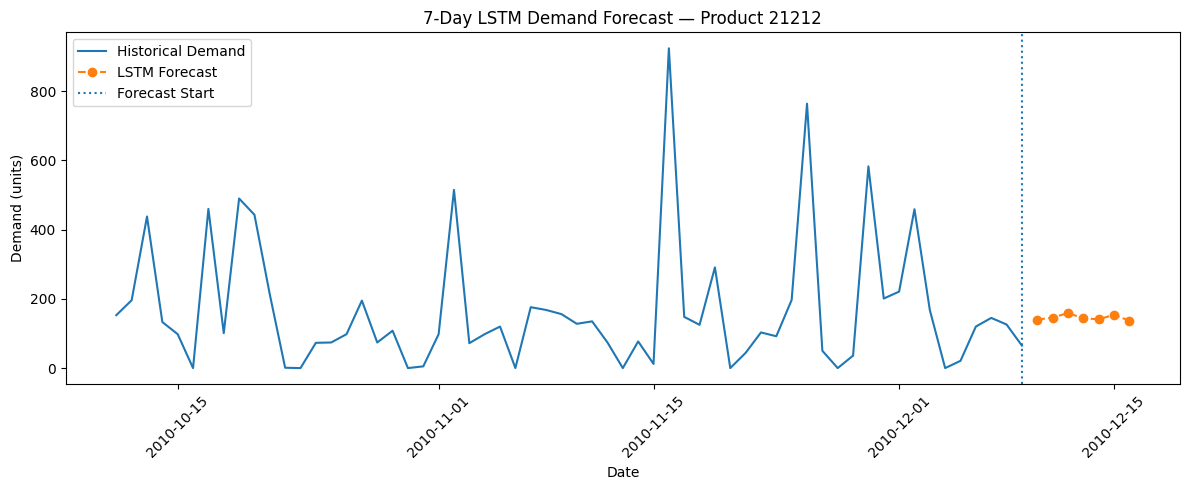

In [35]:
# Plot the forecast

plt.figure(figsize=(12, 5))

plt.plot(
    series.tail(60).index,
    series.tail(60).values,
    label="Historical Demand"
)

plt.plot(
    forecast_df["Date"],
    forecast_df["ForecastedDemand"],
    marker="o",
    linestyle="--",
    label="LSTM Forecast"
)

plt.axvline(series.index.max(), linestyle=":", label="Forecast Start")

plt.title(f"7-Day LSTM Demand Forecast — Product {selected_product}")
plt.xlabel("Date")
plt.ylabel("Demand (units)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
# Generate rolling 7-day forecasts for the test period

lookback = 28
forecast_horizon = 7
test_days = 30

values = series.to_numpy(dtype=np.float32)
split_idx = len(values) - test_days

if split_idx < lookback:
    raise ValueError("Not enough historical data for this test setup.")

# The scaler should have been fitted on training data only.
# This code assumes your earlier split_idx and scaler were created
# using the same final-30-day test split.
model.eval()
device = next(model.parameters()).device

predictions = []
actuals = []
forecast_origins = []

# Forecast in 7-day blocks across the final 30 days.
# Each block uses only observations available before its forecast origin.
for start in range(split_idx, len(values), forecast_horizon):
    end = min(start + forecast_horizon, len(values))

    history = values[:start]
    if len(history) < lookback:
        continue

    # Transform history using the already-fitted scaler
    history_scaled = scaler.transform(
        history.reshape(-1, 1)
    ).astype(np.float32)

    x = torch.tensor(
        history_scaled[-lookback:]
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        pred_scaled = model(x).cpu().numpy().reshape(-1, 1)

    pred = scaler.inverse_transform(pred_scaled).flatten()

    # Keep only predictions corresponding to the current test block
    block_length = end - start
    predictions.extend(np.maximum(pred[:block_length], 0))
    actuals.extend(values[start:end])
    forecast_origins.extend(series.index[start:end])

y_true = np.asarray(actuals)
y_pred = np.asarray(predictions)

print("Test observations:", len(y_true))
print("Forecast observations:", len(y_pred))

Test observations: 30
Forecast observations: 30


In [37]:
# Calculate MAE and RMSE

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

print(f"LSTM MAE:  {mae:.2f}")
print(f"LSTM RMSE: {rmse:.2f}")

LSTM MAE:  135.64
LSTM RMSE: 222.91


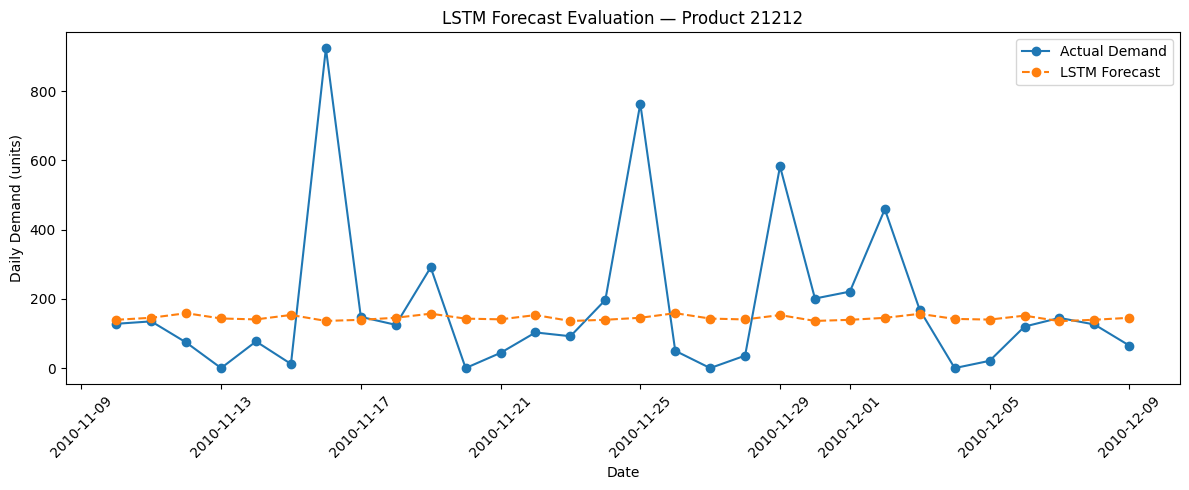

,Date,ActualDemand,PredictedDemand
0,2010-11-10,128.0,139.550003
1,2010-11-11,135.0,145.429993
2,2010-11-12,74.0,158.610001
3,2010-11-13,0.0,143.360001
4,2010-11-14,77.0,140.669998
5,2010-11-15,12.0,153.520004
6,2010-11-16,924.0,136.300003
7,2010-11-17,148.0,139.449997
8,2010-11-18,125.0,145.470001
9,2010-11-19,291.0,157.199997


In [38]:
# Plot actual versus predicted demand

evaluation_df = pd.DataFrame({
    "Date": forecast_origins,
    "ActualDemand": y_true,
    "PredictedDemand": y_pred
})

plt.figure(figsize=(12, 5))
plt.plot(
    evaluation_df["Date"],
    evaluation_df["ActualDemand"],
    marker="o",
    label="Actual Demand"
)
plt.plot(
    evaluation_df["Date"],
    evaluation_df["PredictedDemand"],
    marker="o",
    linestyle="--",
    label="LSTM Forecast"
)

plt.title(f"LSTM Forecast Evaluation — Product {selected_product}")
plt.xlabel("Date")
plt.ylabel("Daily Demand (units)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(evaluation_df.round(2))


,Model,MAE,RMSE
0,7-Day Moving Average,131.18,229.29
1,Historical Mean,137.59,221.59
2,LSTM,135.64,222.91


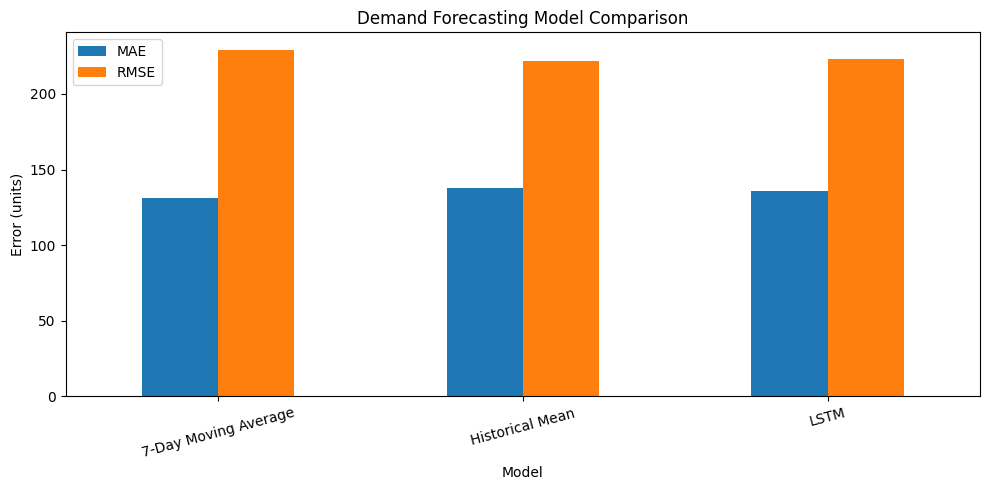

In [39]:
# Create a model comparison chart

comparison_df = pd.DataFrame({
    "Model": [
        "7-Day Moving Average",
        "Historical Mean",
        "LSTM"
    ],
    "MAE": [131.18, 137.59, 135.64],
    "RMSE": [229.29, 221.59, 222.91]
})

display(comparison_df)

comparison_df.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Demand Forecasting Model Comparison")
plt.ylabel("Error (units)")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
# Set inventory planning assumptions

# Inventory planning assumptions
lead_time_days = 7
review_period_days = 7
service_level_z = 1.645  # Approx. 95% service level

# Check forecast data
display(forecast_df)

,Date,StockCode,ForecastedDemand
0,2010-12-10,21212,140
1,2010-12-11,21212,146
2,2010-12-12,21212,159
3,2010-12-13,21212,144
4,2010-12-14,21212,141
5,2010-12-15,21212,154
6,2010-12-16,21212,137


In [41]:
# Calculate forecast-based inventory recommendations

# Forecasted demand for the next 7 days
forecast_values = forecast_df["ForecastedDemand"].to_numpy(dtype=float)

forecasted_lead_time_demand = forecast_values[:lead_time_days].sum()

# Estimate daily demand from the forecast
forecast_avg_daily_demand = forecast_values.mean()

# Historical daily demand variability
daily_demand_std = float(series.std(ddof=1))

if np.isnan(daily_demand_std):
    daily_demand_std = 0.0

# Safety stock based on historical variability
safety_stock = service_level_z * daily_demand_std * np.sqrt(lead_time_days)

# Reorder point uses forecasted lead-time demand
reorder_point = forecasted_lead_time_demand + safety_stock

# Approximate demand over lead time + review period.
# The 7-day forecast is reused as the estimate for the review period.
target_stock = (
    forecasted_lead_time_demand
    + forecast_avg_daily_demand * review_period_days
    + safety_stock
)

inventory_recommendation = pd.DataFrame([{
    "StockCode": selected_product,
    "ForecastedLeadTimeDemand": int(np.ceil(forecasted_lead_time_demand)),
    "ForecastAvgDailyDemand": round(forecast_avg_daily_demand, 2),
    "HistoricalDailyDemandStd": round(daily_demand_std, 2),
    "LeadTimeDays": lead_time_days,
    "ReviewPeriodDays": review_period_days,
    "SafetyStock": int(np.ceil(safety_stock)),
    "ReorderPoint": int(np.ceil(reorder_point)),
    "TargetStock": int(np.ceil(target_stock))
}])

display(inventory_recommendation)

,StockCode,ForecastedLeadTimeDemand,ForecastAvgDailyDemand,HistoricalDailyDemandStd,LeadTimeDays,ReviewPeriodDays,SafetyStock,ReorderPoint,TargetStock
0,21212,1021,145.86,184.35,7,7,803,1824,2845


In [42]:
# Save your inventory recommendation

output_file = os.path.join(DATA_DIR, "forecast_based_inventory_recommendation.csv")

inventory_recommendation.to_csv(output_file, index=False)

print("Saved:", output_file)

from google.colab import files
files.download(output_file)

Saved: forecast_based_inventory_recommendation.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>